   ... mutation simply refers to the ability to physically overwrite data    
   directly in memory, which is the preferred approach for building 
   collections in other non-functional languages. ... instead of creating a 
   brand new copy of a list every time you add an element, mutation lets a 
   program change the existing structure in place. Because pure functional 
   languages like Haskell strictly forbid this destructive modification...

   difference lists act as the king of efficient data construction by 
   avoiding massive memory copying overheads. The text points out that
   even when mutation is available, directly modifying shared memory
   becomes incredibly danerous in parallel computing contexts. As you push 
   ... remember that generating assembly instructions for your WACC compiler
   will likely rely on these difference lists to efficiently stitch sequences
   together without destroying performance... 

-- ... REFERENTIAL TRANSPARENCY. Because values never change in place, any
   function given the same inputs will always return the exact same output. 
   The compiler relies on this guarantee to freely reorder, parallelize, or
   lazily delay evaluatins without breaking program logic... 

-- 

   The implementation of a difference list is formally defined as 
   `newtype DList a = DList ([a] -> [a])`. Function composition does not 
   delay execution purely because of laziness, but because functions
   fundamentally require a final input argument to resolve. ... When you append 
   sequences using `dxs . dys`, you are physically constructing a brand new
   function in memory rather than iterating through data. The combined function
   is completely incapable of executing until it receives an actual list to 
   operate on ... 

   Because this structure is literally just a pending function, you cannot
   traverse it directly to read the internal elements. You must first convert it
   back into a standard data list by calling `toList dxs = dxs []`. Feeding
   the empty list into this function chain finally triggers the execution,
   cleanly unwinding the nested closures into a standard list from right to left
   . If you attempt to use standard sequence operations like `head` or `tail`
   on a difference list, the interface automatically forces this `toList`
   conversion under the hood before performing the lookup. This mandatory
   conversion requires O(n) time, reinforcing that `DList`s are explicitly
   optimised for fast construction rather than efficient reading. 
   

   ... introduces the fundmanetal algorithmic paradigms of divide-and-conquer,
   alongside dynamic programming. It defines divide-and-conquer as a strict
   three-step framework for solving complex computatinal tasks. The algo
   must first fracture a large primary problem into much smaller sub-problems...
   It then converts the most trivial base cases directly into usable 
   sub-solutions. The final step involves merging those individual sub-solutions
   back together, which forms the ultimate answer. 

   ... text applies this theoretical framework to the classic merge sort
   algorithm. It demonstrates the first necessary division step by writing
   helper functions to split lists. The baseline approach uses a built-in 
   operation, allowing the program to slice sequences at a specific index. The
   customised implementation calculates the exact mathematical midpoint to 
   evenly halve the target list structure. This halving technique perfectly
   satisfies the first requirement, successfully ... 

   ... introduces dynamic programming by demonstrating how it fixes a highly
   inefficient D&C algorithm. The text uses a naive recursive Fiboonacci 
   function to illustrate a core failure: the algorithm recalculates the exact
   same sub-problems over and over again, like computing `fib 2` multiple times.
   This massive amount of duplicated work completely ruins performance ...
   causing the time complexity to erode exponentially into O(2^n). The goal of
   dynamijc programming is to maintain the clean formulation of D&C while 
   completely eliminating this duplicated effort by catching and caching those
   overlapping sub-problems. 

   To build this cache in Haskell, the text proposes using an immutable array
   to act as an efficient lookup table. It introduces the `Ix` index class and
   a helper function called `tabulate`, which creates an array by evaluating a
   provided function across a defined range of indices. Because Haskell relies
   on lazy evaluation, it can declare this array using a recursive function
   that looks back at the table itself without causing an immediate infinite
   loop. Thge array elements are stored as uncomputed thunks, which evaluate
   only once when demanded, automatically caching the results for all future
   lookups and slashing the exponential cost down to a linear O(n)...



fib 5 
fib 5 = fib 4 + fib 3
      = (fib 3 + fib 2) + (fib 2 + fib 1)
      = (fib 2 + fib 1 + fib 1 + fib 0) + fib 1 + fib 0 + fib 1
      = 2 + 1 + 1 + 1 + 1 + 1 + 1

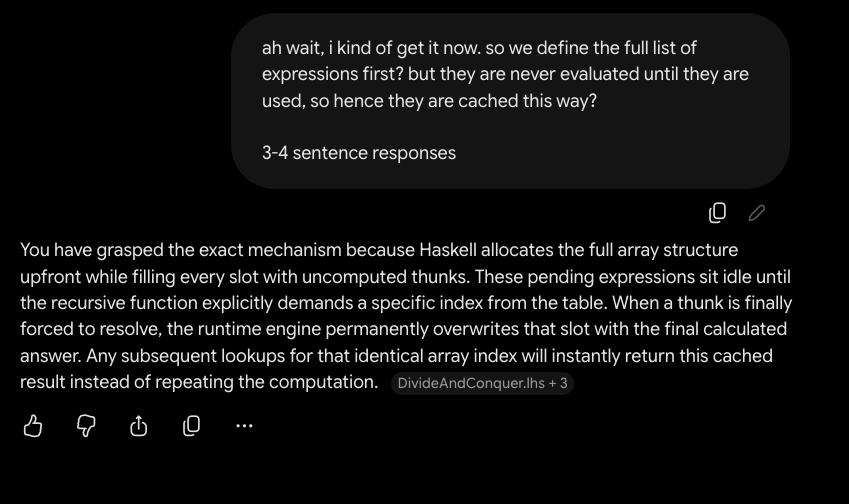

-- .... a THUNK is an unevaluated expression stored in memory. Because Haskell
   uses lazy evaluation, expressions are not computed immediately when they are
   defined ... instead, the runtime wraps the recipe for computing the value
   inside a thunk and waits until the result is actually needed ... 

-- At its core, dynamic programming solves complex problems by breaking them 
   down into simpler overlapping subproblems. Instead of recalculating the 
   same intermediate steps repeatedly, this technique computes each subproblem
   once and stores the result in a memory table. When the algorithm encounters 
   that same subproblem again, it retrieves the saved answer instantly. By 
   building up solutions from the smallest base cases, dynamic programming 
   transforms slow exponential searches into fast polynomial algorithms ... 

-- ALGEBRAIC DATA TYPES (`data`)
   The `data` keyword is the standard and most versatile way to define custom
   data structures, supporting both PRODUCT TYPES (multiple fields grouped
   together) and SUM TYPES (choosing between multiple alternatives or
   constructors)

```hs
-- 
data Direction = North | South | East | West
```
   



-- The `type` keyword does not create a new data structure at all; it simply
   introduces an alias or alternative name for an existing type to improve code
   readability

```hs
type Name = String
type Database = [(Name, Int)]
```

```hs
> fib'' :: Int -> Integer
> fib'' n = loop 1 1 n
>   where loop :: Integer -> Integer -> Int -> Integer
>         loop i j 0 = i
>         loop i j 1 = j
>         loop i j n = loop j (i + j) (n-1)
```
1 1 2 3 5 8 13 21
0 1 2 3 4 5 6  7
```haskell
loop 1 1 4 
= loop 1 1+1 3
= loop 1 2 3
= loop 2 3 2
= loop 3 5 1 
= 5

loop 1 1 3
= loop 1 1+1 3-1
= loop 1 2 2
= loop 2 1+2 2-1
= loop 2 3 1
= 3
```


   ... trace its lazy evaluation path for a small target like three pence...
   When you call the function, it allocates a full array in memory 
   populated entirely by uncomputed thunks. The engine specifically demands
   the third index, which forces the third thunk to evaluate its minimum coin
   possibilities. This calculation requires looking up the array values for 
   two pence and one pence ... which forces those prior thunks to recursively
   unpack themselves... The recursion continually cascades backward, until it
   finally hits the zero index base case...

   

range :: Ix i => (i, i) -> [i]

range (0, 3)
= [0, 1, 2, 3]

range (1, 5)
= [1 .. 5]
= [1,2,3,4,5]

inRange (1, 5) 3
= 1 <= 3 && 3 <= 5
= True && True
= True

inRange (1, 5) 7
= 1 <= 7 && 7 <= 5
= True && False
= False


---

    // index: Takes a bounds pair (lower, upper) and a specific value within that range, returning its zero-based integer offset/position.

index (1, 5) 3
= -- inRange (1, 5) 3 = True, take first guard
= 3 - 1
= 2                      -- 3 is the third slot, and slots count from 0

index (1, 5) 7
= -- inRange (1, 5) 7 = False, take second guard
= error "Ix: index out of range"


---


#
rangeSize (1, 5)
= -- 1 <= 5, take first guard
= index (1, 5) 5 + 1
= (5 - 1) + 1
= 5




---


`a = key`
`b = val`
    `array is just KV pairs in Haskell, it's just called array because in `
    `Hakell, arrayS have array-level performances of other programs`
    ` - don't forget that ARRAYs are immutable in Haskell`
array :: Ix a => (a, a) -> [(a, b)] -> Array a b


squares :: Array Int Int
squares = array (1, 5) [(i, i * i) | i <- [1..5]]

let charArr = array (0, 3) [(0, 'a'), (1, 'b'), (2, 'c'), (3, 'd')]





---
---

   ... the `array` function builds an immutable, indexed array from a pair of
   bounds and a list of index-value associations (an association list)...


```haskell
tabulate :: Ix i => (i, i) -> (i -> a) -> Array i a
tabulate bounds f = array bounds [(i, f i) | i <- range bounds]
```

```haskell
tabulate (3, 5) (\x -> x + 3)
= array (3, 5) [(i, f i) | i <- [3, 4, 5]]
= array (3, 5) [(3, 6), (4, 7), (5, 8)]
```

```haskell
let numArr = tabulate (3, 5) (\x -> x + 3)
let numArr = array (3, 5) [(3, 6), (4, 7), (5, 8)]
numArr ! 4 = 7
```

```haskell
> fib' :: Int -> Integer -- O(n)
> fib' n = table ! n
>   where table :: Array Int Integer
>         table = tabulate (0, n) memo
>
>         memo :: Int -> Integer
>         memo 0 = 1
>         memo 1 = 1
>         memo n = table ! (n - 1) + table ! (n - 2)
```


```haskell
> change :: Pence -> Int -- O(8^n)
> change 0 = 0
> change g = minimum [ change (g - coin) + 1 | coin <- coins, coin <= g]

---

> type Pence = Int
> coins :: [Pence]
> coins = [1, 2, 5, 10, 20, 50, 100, 200]


change g 
= minimum [ change (g - coin) + 1 | coin <- coins, coin <= g]
change 2 
= minimum [ change (2 - coin) + 1 | coin <- [1, 2, 5, 10, 20, 50, 100, 200], coin <= 2]
= minimum [ change (2 - coin) + 1 | coin <- [1, 2]]
= minimum [ change (2 - 1) + 1, change (2 - 2) + 1]
= minimum [ change 1 + 1, change 0 + 1]
= minimum [ change 1 + 1, 1]
= minimum [ 1 + 1, 1 ]
= minimum [ 2, 1 ]
= 1

    change 1
    = minimum [ change (1 - 1) + 1 | coin <- [1], coin <= 1]
    = minimum [ 0 + 1 ]
    = 1
```

-- `Ix` stands foor INDEX
   ... `Ix` is a standard type class (`class Ord a => Ix a where`) defined in 
   the `Data.Ix` module. It is used too map a contiguous subrange of values
   in a type onto a linear sequence of integers... 

WEEK 4
WEEK 6
Coursework coding begins <--
git commit modify pre-pushing to change commit times
proceed with writeup for 50001 - CW1
submit writeup for CW1